# Part 1 - 3. GLM
Single subject, single run (HCP language task, story vs math).

Run the cells in order, with the `neural_signal` kernel, from the repository folder.

Inputs: the outputs of part 1-2 (functional preprocessing, `Project_notebook.ipynb`, sections 4-5),
in `data/derivatives/func/`. Run the notebook first.
- `func_mc_brain_smooth6mm.nii.gz`: run without the first 3 volumes, motion-corrected, masked, smoothed;
- `task_onsets_used.csv`: onsets shifted by 3 x TR to match the trimmed run;
- `motion_confounds.txt`: the 6 MCFLIRT parameters (+ one spike regressor per volume with FD > 0.5 mm, none here).

- **3a** Design matrix
- **3b** Correlation between the regressors

In [1]:
import os
import os.path as op

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from nilearn.glm.first_level import make_first_level_design_matrix
from nilearn.plotting import plot_design_matrix

# Paths relative to the notebook folder: works on every machine without editing
root_dir = op.abspath(".")
data_dir = op.join(root_dir, "data")
out_dir = op.join(data_dir, "derivatives")
glm_dir = op.join(out_dir, "glm")
fig_dir = op.join(out_dir, "figures")
for d in (glm_dir, fig_dir):
    os.makedirs(d, exist_ok=True)
FIG_DPI = 300

# Outputs of part 1-2 (functional preprocessing)
FWHM = 6                                            # mm, smoothing chosen in part 1-2
func_dir = op.join(out_dir, "func")
func_img_path = op.join(func_dir, f"func_mc_brain_smooth{FWHM}mm.nii.gz")
events_path = op.join(func_dir, "task_onsets_used.csv")         # onsets in the time frame of the trimmed run
confounds_path = op.join(func_dir, "motion_confounds.txt")      # rx ry rz (rad), tx ty tz (mm), spikes

for path in (func_img_path, events_path, confounds_path):
    assert op.exists(path), f"{path} not found: run part 1-2 of Project_notebook.ipynb first"

## Acquisition parameters and events

In [2]:
func_header = nib.load(func_img_path).header        # header only, the 4D data is not loaded
n_scans = func_header.get_data_shape()[3]
t_r = float(func_header.get_zooms()[3])
frame_times = np.arange(n_scans) * t_r              # same convention as FirstLevelModel (slice_time_ref=0)
print(f"{n_scans} volumes, TR = {t_r} s, run duration = {n_scans * t_r:.1f} s")

events = pd.read_csv(events_path)
print(events.groupby("trial_type")["duration"].agg(["count", "mean", "sum"]).round(2))

313 volumes, TR = 0.7200000286102295 s, run duration = 225.4 s
                count   mean     sum
trial_type                          
cue                 7   0.77    5.38
math                9  12.08  108.72
present_math        9   5.46   49.14
present_story       4  19.55   78.19
question_math       9   3.45   31.09
question_story      4   1.16    4.64
response_math       9   2.96   26.66
response_story      4   2.96   11.84
story               4  27.22  108.87


## 3a. Design matrix

The event file contains two levels of description:
- the **blocks** `story` and `math` (~12-30 s each), which alternate without rest;
- the **sub-events** inside each block: `present_*` (listening to the story / the operations),
  `question_*` (2-alternative question), `response_*` (button press), and the short auditory
  `cue` before each block.

The two levels overlap in time, so they cannot be put in the same model (a block is almost the sum
of its sub-events). We build:
1. **Block design (main model)**: `story`, `math`. This answers the question of the project (story vs
   math) with the most power, and is the design used by Binder et al. (2011) and HCP.
2. **Event design (detailed model)**: the 7 sub-events. Used to discuss the collinearity in 3b and for the
   theoretical questions (question vs response, processing vs preparation).

Common settings, following lab 5:
- **HRF**: canonical SPM (double gamma); each regressor = boxcar of the condition convolved with the HRF.
- **Drifts**: cosine basis with a 0.01 Hz high-pass cut-off (100 s). The task alternates story/math
  with a period of ~55-60 s (~0.017 Hz), above the cut-off, so the drift terms do not absorb the task.
- **Constant**: intercept.
- **Motion**: the 6 MCFLIRT parameters of part 1-2 as nuisance regressors (no spike regressor: no volume
  has FD > 0.5 mm). The motion is small (mean FD 0.10 mm), but it costs only 6 degrees of freedom out of 313.

In [3]:
HRF_MODEL = "spm"
DRIFT_MODEL = "cosine"
HIGH_PASS = 0.01                                    # Hz

BLOCK_CONDITIONS = ["story", "math"]
EVENT_CONDITIONS = ["present_story", "question_story", "response_story",
                    "present_math", "question_math", "response_math", "cue"]

# Motion confounds (part 1-2)
motion = np.loadtxt(confounds_path, ndmin=2)
assert motion.shape[0] == n_scans, "confounds and fMRI run must have the same number of volumes"
motion_names = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]
motion_names += [f"spike_{k}" for k in range(motion.shape[1] - 6)]


def build_design(conditions):
    """First-level design matrix for a subset of the event types."""
    ev = events[events["trial_type"].isin(conditions)]
    return make_first_level_design_matrix(frame_times, ev, hrf_model=HRF_MODEL,
                                          drift_model=DRIFT_MODEL, high_pass=HIGH_PASS,
                                          add_regs=motion, add_reg_names=motion_names)


dm_block = build_design(BLOCK_CONDITIONS)
dm_event = build_design(EVENT_CONDITIONS)
drift_cols = [c for c in dm_block.columns if c.startswith("drift")]
print("Block design:", dm_block.shape, list(dm_block.columns))
print("Event design:", dm_event.shape, list(dm_event.columns))

# Saved for the GLM (3c-3d) and for part 2 (correlation of the K-means clusters with the regressors)
dm_block.to_csv(op.join(glm_dir, "design_matrix_block.csv"))
dm_event.to_csv(op.join(glm_dir, "design_matrix_event.csv"))

Block design: (313, 13) ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']
Event design: (313, 18) ['cue', 'present_math', 'present_story', 'question_math', 'question_story', 'response_math', 'response_story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']


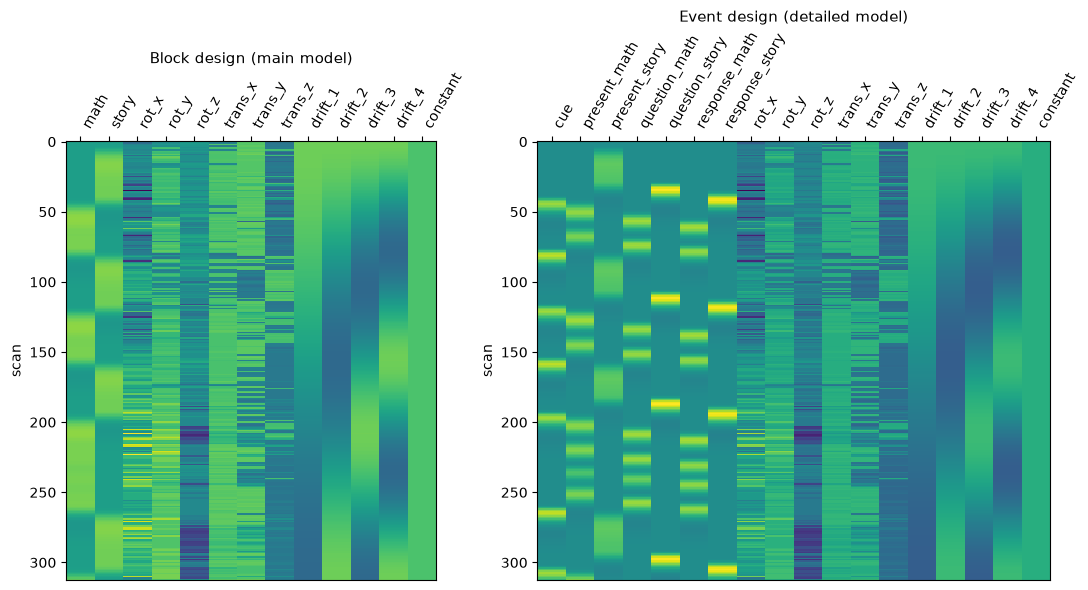

In [4]:
# Figure: both design matrices side by side
fig, axs = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={"width_ratios": [dm_block.shape[1], dm_event.shape[1]]})
plot_design_matrix(dm_block, axes=axs[0])
axs[0].set_title("Block design (main model)", fontsize=11)
plot_design_matrix(dm_event, axes=axs[1])
axs[1].set_title("Event design (detailed model)", fontsize=11)
for ax in axs:
    ax.set_ylabel("scan")
fig.tight_layout()
fig.savefig(op.join(fig_dir, "7a_design_matrix.png"), dpi=FIG_DPI)
plt.show()

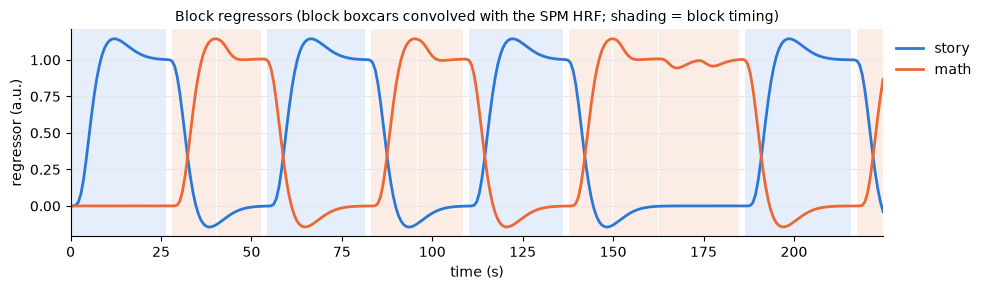

In [5]:
# Figure: task regressors of the block design over time, with the blocks shaded
STORY_COLOR, MATH_COLOR = "#2a78d6", "#eb6834"
fig, ax = plt.subplots(figsize=(10, 3))
for _, ev in events[events["trial_type"].isin(BLOCK_CONDITIONS)].iterrows():
    color = STORY_COLOR if ev["trial_type"] == "story" else MATH_COLOR
    ax.axvspan(ev["onset"], ev["onset"] + ev["duration"], color=color, alpha=0.12, lw=0)
ax.plot(frame_times, dm_block["story"], color=STORY_COLOR, lw=2, label="story")
ax.plot(frame_times, dm_block["math"], color=MATH_COLOR, lw=2, label="math")
ax.set_xlabel("time (s)")
ax.set_ylabel("regressor (a.u.)")
ax.set_xlim(0, frame_times[-1])
ax.set_title("Block regressors (block boxcars convolved with the SPM HRF; shading = block timing)", fontsize=10)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9")
fig.tight_layout()
fig.savefig(op.join(fig_dir, "7a_block_regressors.png"), dpi=FIG_DPI)
plt.show()

## 3b. Correlation between the regressors

Pearson correlation between the columns of each design matrix. The constant is left out (zero variance).
The variance inflation factor (VIF = 1 / (1 - R²) of each regressor regressed on all the others,
constant included) summarises how much each beta's variance is inflated by collinearity.

In [6]:
def vif(dm, columns):
    """Variance inflation factor of each column, regressed on all the other columns of dm."""
    out = {}
    for col in columns:
        y = dm[col].to_numpy()
        X = dm.drop(columns=col).to_numpy()
        resid = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
        r2 = 1 - resid.var() / y.var()
        out[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out)


corr_block = dm_block.drop(columns="constant").corr()
corr_event = dm_event.drop(columns="constant").corr()
print("Block design correlations (task regressors):\n", corr_block.loc[BLOCK_CONDITIONS, BLOCK_CONDITIONS].round(3))
print("\nVIF block design:\n", vif(dm_block, BLOCK_CONDITIONS).round(2))
print("\nVIF event design:\n", vif(dm_event, EVENT_CONDITIONS).round(2))

# Largest absolute correlations between task regressors of the event design
task_corr = corr_event.loc[EVENT_CONDITIONS, EVENT_CONDITIONS]
pairs = (task_corr.where(np.triu(np.ones(task_corr.shape, bool), k=1)).stack()
         .sort_values(key=np.abs, ascending=False))
print("\nEvent design, strongest task correlations:\n", pairs.head(6).round(3))

# Task-correlated motion: a motion regressor that follows the task would remove task signal
print("\nCorrelation of the motion parameters with the block regressors:\n",
      corr_block.loc[motion_names, BLOCK_CONDITIONS].round(3))
print("\nCorrelation of the motion parameters with the drifts (max |r|):\n",
      corr_block.loc[motion_names, drift_cols].abs().max(axis=1).round(3))

Block design correlations (task regressors):
        story   math
story  1.000 -0.943
math  -0.943  1.000

VIF block design:
 story    10.50
math     12.14
dtype: float64

VIF event design:
 present_story     12.63
question_story     2.96
response_story     4.63
present_math       6.70
question_math      4.06
response_math      3.89
cue                2.02
dtype: float64

Event design, strongest task correlations:
 present_story   present_math     -0.562
response_story  cue               0.504
present_story   question_math    -0.486
question_math   response_math     0.471
present_story   response_math    -0.400
                response_story   -0.347
dtype: float64

Correlation of the motion parameters with the block regressors:
          story   math
rot_x    0.114 -0.074
rot_y   -0.143  0.204
rot_z   -0.074  0.034
trans_x -0.183  0.254
trans_y -0.170  0.133
trans_z  0.014  0.007

Correlation of the motion parameters with the drifts (max |r|):
 rot_x      0.624
rot_y      0.527
rot_z 

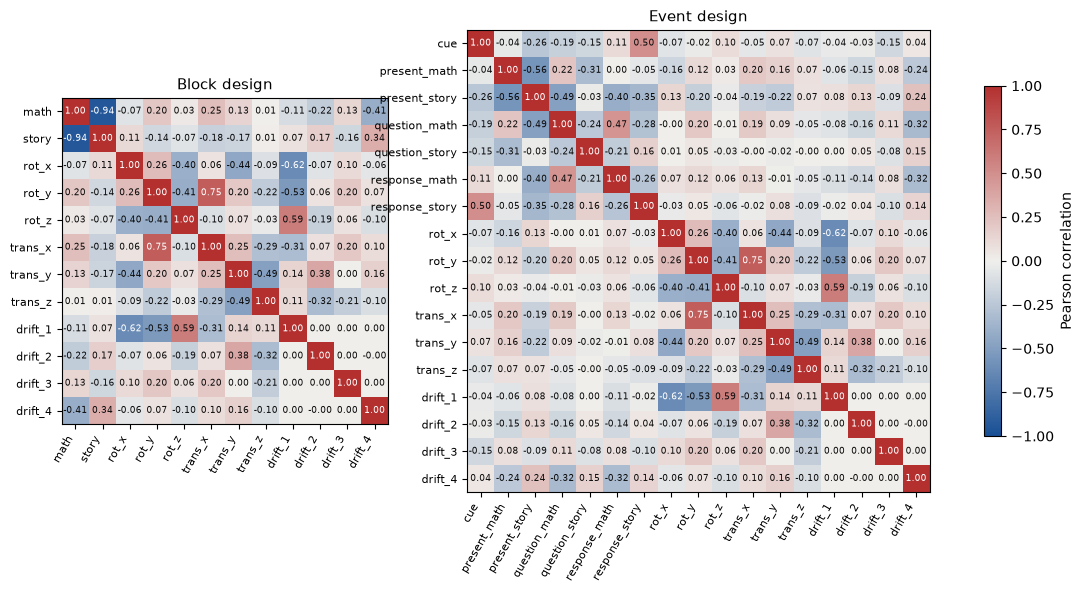

In [7]:
# Figure: correlation matrices (diverging blue - gray - red, symmetric -1..1)
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#f0efec", "#b3302f"])


def plot_corr(corr, ax, title):
    n = len(corr)
    im = ax.imshow(corr.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(n), corr.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(n), corr.index, fontsize=8)
    for i in range(n):
        for j in range(n):
            v = corr.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(v) > 0.6 else "#0b0b0b")
    ax.set_title(title, fontsize=11)
    return im


fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [len(corr_block), len(corr_event)]})
plot_corr(corr_block, axs[0], "Block design")
im = plot_corr(corr_event, axs[1], "Event design")
fig.colorbar(im, ax=axs, shrink=0.7, label="Pearson correlation")
fig.savefig(op.join(fig_dir, "7b_regressor_correlation.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on 3b

Values for the preprocessed run of part 1-2: 313 volumes (first 3 removed), onsets shifted by 3 x TR.

**Block design: `story` and `math` are strongly anti-correlated (r = -0.94, VIF 10.5 and 12.1).**
The blocks alternate with no rest: 94.5% of the run (213 of 225.4 s) is covered by either a story or a math
block. Only ~12.4 s (cues and gaps) are left as the implicit baseline. So `story + math` ≈ constant, and
the two regressors are almost collinear with each other and with the intercept.
- Consequence for **3c**: the individual betas (story alone, math alone) are poorly estimated (variance
  inflated ~10×). They do not mean "versus rest", only "versus the ~12 s of cues/gaps". Their maps must be
  read with caution, and they mostly show what is common to both tasks (auditory input, attention, button press).
- Consequence for **3d**: the **story − math** contrast is well estimated. It lies along the direction where
  the design varies most (the alternation itself). This is the robust result of the GLM, and the reason the
  task was designed with matched math blocks (Binder et al., 2011).

The last math block starts at 217.4 s and is cut by the end of the run (8 s of its 12.6 s are acquired);
its regressor is simply truncated.

**Drifts.** `drift_4` (cosine of period ~113 s) correlates with the task (r = 0.34 with story, -0.41 with
math). The four consecutive math blocks between 138 and 187 s give the task some low-frequency content, which
the 0.01 Hz high-pass partly competes with. The correlation stays moderate. A lower cut-off (e.g. 1/128 Hz,
the SPM default) would reduce it, at the cost of less drift removal.

**Motion.** The 6 motion parameters are only weakly correlated with the task (|r| ≤ 0.25, largest for
`trans_x` with math), so there is no sign of task-correlated motion, and adding them as confounds removes
little task signal. They are more correlated with the slow drifts (|r| up to 0.62 between the rotations and
`drift_1`): part of the "motion" is a slow drift of the head or of the realignment estimate, which the two
sets of regressors share. Between themselves, `rot_y` and `trans_x` correlate at 0.75 (a rotation around y
moves the brain's centre of mass along x).

**Event design.** The correlations follow the timeline of each trial:
- `present_story` vs `present_math` (r = -0.56): they alternate;
- `response_story` vs `cue` (r = 0.50): the cue starts ~0.2 s after the story response ends, and the HRF blurs
  the two together;
- `question_math` vs `response_math` (r = 0.47): adjacent ~3 s events.

`present_story` has the highest VIF (12.6): it covers most of each story block, so it is close to a combination
of the other regressors. The short story events (`question_story`, 4 × 1.2 s) carry little signal, hence low
power for the question-vs-response contrasts of the theoretical part.

## 3c. GLM and statistical maps of the task regressors

**Level.** First level (single subject, single run): there is only one subject and one run, so there is
no second level to run. The GLM is fitted voxel by voxel on the preprocessed run of part 1-2, with the
design matrices of 3a passed directly (same regressors, same drifts, same motion confounds).

Settings, following lab 5:
- **mask**: the functional brain mask of part 1-2 (BET on the mean fMRI);
- **no extra smoothing**: the run is already smoothed (FWHM 6 mm, part 1-2);
- **signal scaling**: each voxel is expressed in % of its mean, so the betas are in % signal change;
- **noise model**: AR(1), because the fMRI noise is autocorrelated at TR = 0.72 s (OLS would underestimate
  the variance and inflate the statistics);
- **thresholding**: FDR q < 0.05 and clusters of at least 10 voxels (`threshold_stats_img`, as in lab 5).
  The maps are z-scores, two-sided.

In [8]:
from nilearn.glm.first_level import FirstLevelModel
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table
from nilearn import plotting

func_mask = op.join(func_dir, "func_mean_brain_mask.nii.gz")              # part 1-2
anat_mni = op.join(out_dir, "anat", "T1w_brain_MNI_SyN.nii.gz")          # part 1-1, background of the maps
assert op.exists(func_mask) and op.exists(anat_mni), "run parts 1-1 and 1-2 of Project_notebook.ipynb first"

FDR_ALPHA = 0.05
CLUSTER_SIZE = 10                                   # voxels
Z_CUTS = [-24, -12, -4, 4, 14, 26, 40, 52]          # axial slices (MNI z, mm)
Z_VMAX = 10                                         # common colour scale for all the maps


def fit_glm(design):
    glm = FirstLevelModel(t_r=t_r, mask_img=func_mask, smoothing_fwhm=None, noise_model="ar1",
                          signal_scaling=0, minimize_memory=True)
    return glm.fit(func_img_path, design_matrices=design)


def contrast_vector(design, weights):
    """Contrast vector over all the columns of the design matrix, from a {column: weight} dict."""
    vec = np.zeros(design.shape[1])
    for col, w in weights.items():
        vec[design.columns.get_loc(col)] = w
    return vec


def threshold(z_map, control="fdr", alpha=FDR_ALPHA):
    """FDR q < 0.05 (two-sided) + cluster extent, as in lab 5. Returns the thresholded map and the z threshold."""
    return threshold_stats_img(z_map, mask_img=func_mask, alpha=alpha, height_control=control,
                               cluster_threshold=CLUSTER_SIZE, two_sided=True)


def plot_map(z_thr, z_thr_value, title, axes, vmax=Z_VMAX):
    display = plotting.plot_stat_map(z_thr, bg_img=anat_mni, display_mode="z", cut_coords=Z_CUTS, axes=axes,
                                     threshold=z_thr_value, vmax=vmax, cmap="RdBu_r", black_bg=False,
                                     annotate=True, draw_cross=False)
    display.title(title, size=9, color="black", bgcolor="white")
    return display


glm_block = fit_glm(dm_block)
glm_event = fit_glm(dm_event)

/var/folders/b7/1yj9d58j6916jyl63yg2qmvm0000gn/T/ipykernel_58340/1221765787.py:19: UserWarning: If design matrices are supplied, [t_r] will be ignored.
  return glm.fit(func_img_path, design_matrices=design)
/var/folders/b7/1yj9d58j6916jyl63yg2qmvm0000gn/T/ipykernel_58340/1221765787.py:19: RuntimeWarning: [MultiNiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  return glm.fit(func_img_path, design_matrices=design)


In [9]:
# Statistical map of each task regressor (each regressor vs the implicit baseline)
z_maps = {}
for name, glm, design, conditions in [("block", glm_block, dm_block, BLOCK_CONDITIONS),
                                      ("event", glm_event, dm_event, EVENT_CONDITIONS)]:
    for cond in conditions:
        z = glm.compute_contrast(contrast_vector(design, {cond: 1}), output_type="z_score")
        z.to_filename(op.join(glm_dir, f"zmap_{name}_{cond}.nii.gz"))
        z_maps[(name, cond)] = z

summary = []
for (name, cond), z in z_maps.items():
    z_thr, thr = threshold(z)
    data = z_thr.get_fdata()
    summary.append({"model": name, "regressor": cond, "z threshold": round(thr, 2),
                    "voxels z>0": int((data > 0).sum()), "voxels z<0": int((data < 0).sum()),
                    "max z": round(float(z.get_fdata().max()), 1), "min z": round(float(z.get_fdata().min()), 1)})
summary = pd.DataFrame(summary)
summary.to_csv(op.join(glm_dir, "regressor_maps_summary.csv"), index=False)
print(summary.to_string(index=False))

model      regressor  z threshold  voxels z>0  voxels z<0  max z  min z
block          story         4.13           0         145    4.4   -5.4
block           math         3.63          21        1116    4.2   -5.5
event  present_story         4.75           0           0    5.3   -5.1
event question_story         3.19        6069         311    6.3   -5.3
event response_story         3.58        1051         328    6.2   -5.4
event   present_math         2.99        8137        4392    7.1   -6.1
event  question_math         3.88         286          77    5.5   -5.0
event  response_math         3.32         946        2843    5.3   -6.7
event            cue         3.44        2501          60    6.9   -4.6


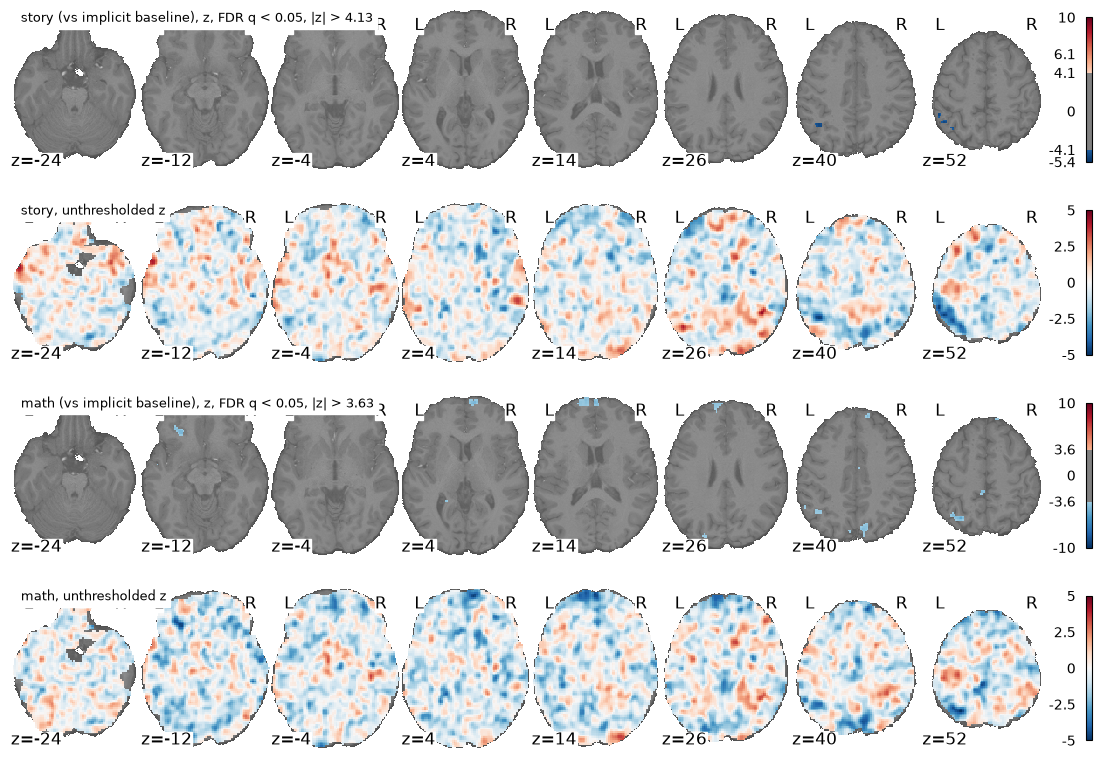

/var/folders/b7/1yj9d58j6916jyl63yg2qmvm0000gn/T/ipykernel_58340/1221765787.py:37: UserWarning: empty mask
  display = plotting.plot_stat_map(z_thr, bg_img=anat_mni, display_mode="z", cut_coords=Z_CUTS, axes=axes,


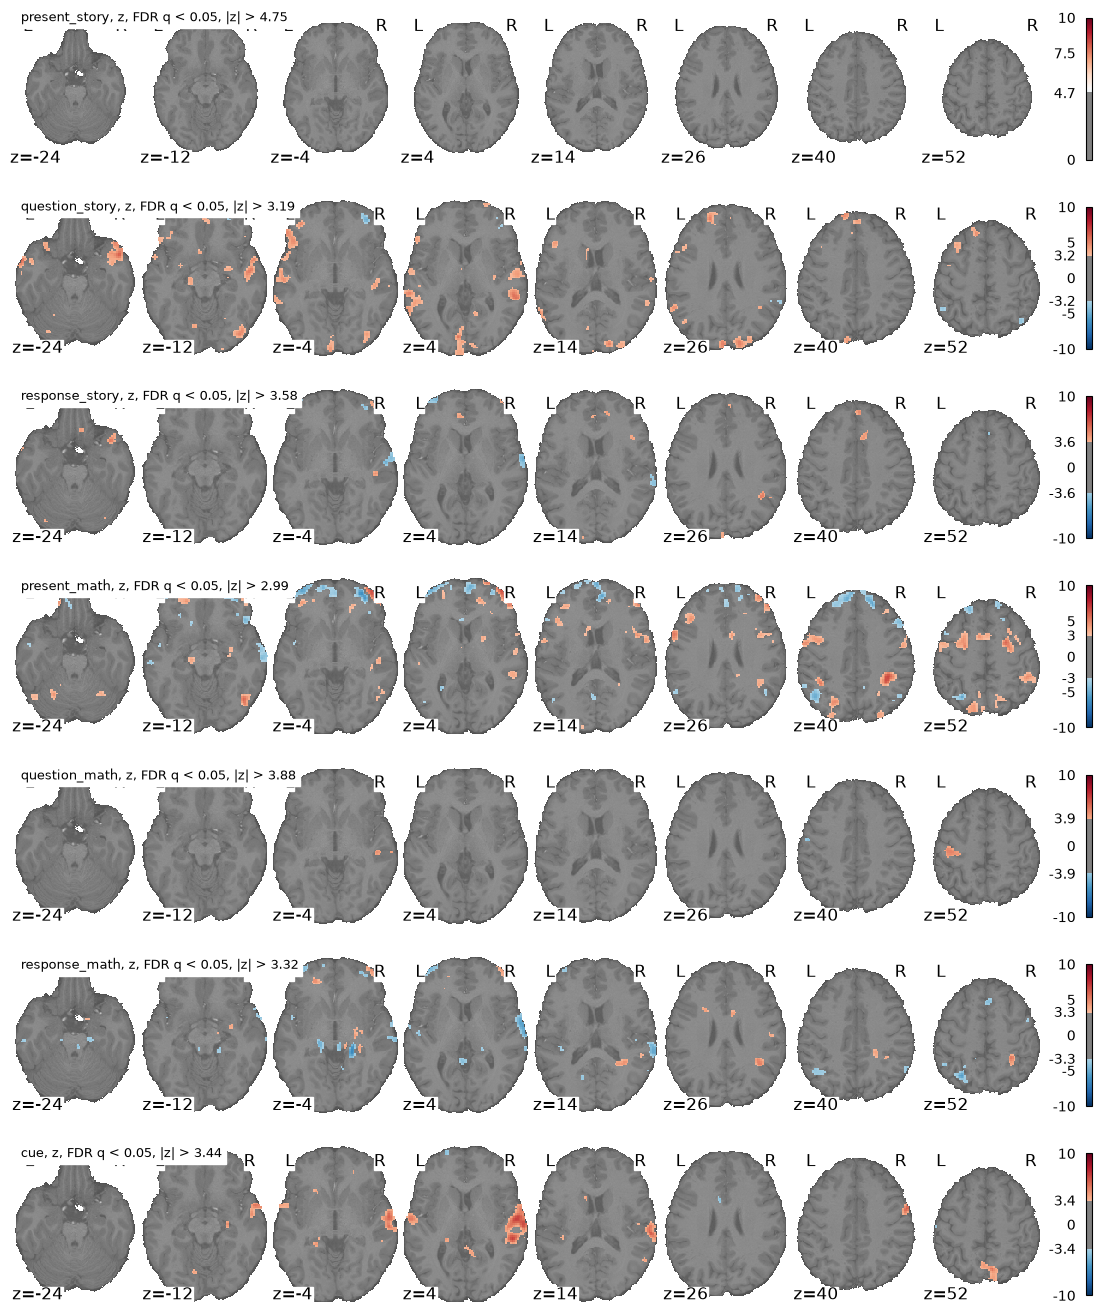

In [10]:
# Figure: block design, two rows per task regressor: thresholded map, then the unthresholded map
# (the thresholded maps are almost empty, see the comments; the raw map shows the spatial pattern behind them)
fig, axs = plt.subplots(2 * len(BLOCK_CONDITIONS), 1, figsize=(14, 2.4 * 2 * len(BLOCK_CONDITIONS)))
for k, cond in enumerate(BLOCK_CONDITIONS):
    z_thr, thr = threshold(z_maps[("block", cond)])
    plot_map(z_thr, thr, f"{cond} (vs implicit baseline), z, FDR q < {FDR_ALPHA}, |z| > {thr:.2f}", axs[2 * k])
    plot_map(z_maps[("block", cond)], 0, f"{cond}, unthresholded z", axs[2 * k + 1], vmax=5)
fig.savefig(op.join(fig_dir, "7c_regressor_maps_block.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

# Figure (appendix): event design, one row per sub-event regressor
fig, axs = plt.subplots(len(EVENT_CONDITIONS), 1, figsize=(14, 2.4 * len(EVENT_CONDITIONS)))
for ax, cond in zip(axs, EVENT_CONDITIONS):
    z_thr, thr = threshold(z_maps[("event", cond)])
    plot_map(z_thr, thr, f"{cond}, z, FDR q < {FDR_ALPHA}, |z| > {thr:.2f}", ax)
fig.savefig(op.join(fig_dir, "annex_regressor_maps_event.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 3d. Story vs math contrast

Contrast vector on the block design (columns in the order of the design matrix):
+1 on `story`, -1 on `math`, 0 on the motion, drift and constant columns. It is printed below.
Positive z = more active during the stories (semantic processing), negative z = more active during math
(numerical processing). The math - story map is the same map with the sign flipped.

In [11]:
c_story_math = contrast_vector(dm_block, {"story": 1, "math": -1})
print("Contrast vector story - math:")
print(pd.Series(c_story_math, index=dm_block.columns).astype(int).to_string())

z_sm = glm_block.compute_contrast(c_story_math, output_type="z_score")
z_sm.to_filename(op.join(glm_dir, "zmap_story_minus_math.nii.gz"))
z_sm_thr, thr_sm = threshold(z_sm)
z_sm_thr.to_filename(op.join(glm_dir, "zmap_story_minus_math_thr.nii.gz"))
d = z_sm_thr.get_fdata()
print(f"\nFDR threshold |z| > {thr_sm:.2f}:  story > math {(d > 0).sum()} voxels,  math > story {(d < 0).sum()} voxels")

clusters = get_clusters_table(z_sm, stat_threshold=thr_sm, cluster_threshold=CLUSTER_SIZE, two_sided=True)
clusters.to_csv(op.join(glm_dir, "clusters_story_minus_math.csv"), index=False)
print(clusters.head(25).to_string(index=False))

Contrast vector story - math:
math       -1
story       1
rot_x       0
rot_y       0
rot_z       0
trans_x     0
trans_y     0
trans_z     0
drift_1     0
drift_2     0
drift_3     0
drift_4     0
constant    0



FDR threshold |z| > 2.42:  story > math 47034 voxels,  math > story 24703 voxels


Cluster ID     X     Y     Z  Peak Stat Cluster Size (mm3)
         1  -4.0  60.0  28.0  10.815451             340208
        1a -20.0  40.0  50.0  10.439586                   
        1b -54.0  -4.0 -10.0  10.193111                   
        1c   0.0  56.0  -8.0  10.172563                   
         2  24.0 -82.0 -44.0   8.373362               8264
        2a  32.0 -70.0 -38.0   6.400430                   
        2b  34.0 -82.0 -34.0   5.733446                   
        2c  18.0 -66.0 -32.0   5.271110                   
         3 -38.0 -72.0 -36.0   6.681596               3440
        3a -32.0 -80.0 -32.0   6.018302                   
        3b -22.0 -84.0 -38.0   3.526422                   
         4  20.0 -18.0 -16.0   5.478980               2384
        4a  16.0  -6.0 -24.0   3.803921                   
        4b  18.0 -16.0 -32.0   3.578416                   
        4c  16.0  -8.0 -36.0   3.180153                   
         5  14.0 -80.0 -16.0   5.255477               59

Bonferroni threshold |z| > 5.19:  story > math 8288 voxels,  math > story 3805 voxels


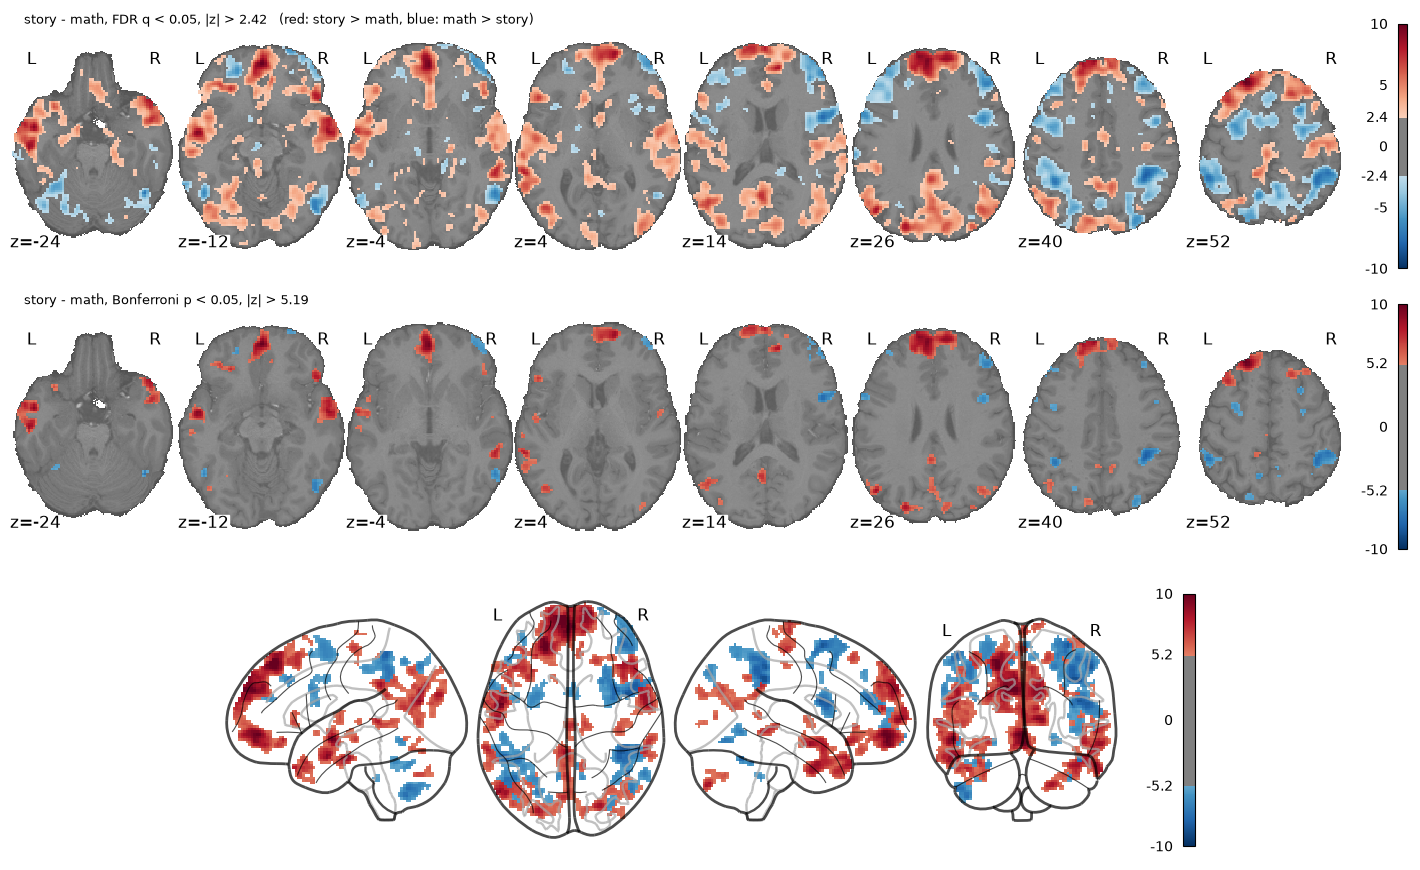

In [12]:
# Stricter control for the figure: Bonferroni (family-wise error) at 0.05, which keeps only the core regions
z_sm_bonf, thr_bonf = threshold(z_sm, control="bonferroni", alpha=0.05)
d = z_sm_bonf.get_fdata()
print(f"Bonferroni threshold |z| > {thr_bonf:.2f}:  story > math {(d > 0).sum()} voxels,  math > story {(d < 0).sum()} voxels")

# Figure: story - math contrast, FDR and Bonferroni, axial slices + glass brain (Bonferroni)
fig = plt.figure(figsize=(14, 8.5))
ax_fdr = fig.add_axes([0, 0.68, 1, 0.32])
ax_bonf = fig.add_axes([0, 0.35, 1, 0.32])
ax_glass = fig.add_axes([0.15, 0, 0.7, 0.33])
plot_map(z_sm_thr, thr_sm, f"story - math, FDR q < {FDR_ALPHA}, |z| > {thr_sm:.2f}   (red: story > math, blue: math > story)", ax_fdr)
plot_map(z_sm_bonf, thr_bonf, f"story - math, Bonferroni p < 0.05, |z| > {thr_bonf:.2f}", ax_bonf)
plotting.plot_glass_brain(z_sm_bonf, threshold=thr_bonf, vmax=Z_VMAX, cmap="RdBu_r", plot_abs=False,
                          colorbar=True, display_mode="lzry", axes=ax_glass)
fig.savefig(op.join(fig_dir, "7d_contrast_story_minus_math.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on 3c

**Block design (`7c_regressor_maps_block.png`).** As predicted in 3b, the maps of `story` alone and `math`
alone are almost empty after FDR correction (story: 145 voxels, math: 1137 voxels, all negative), and the
unthresholded maps look like smooth noise. Each regressor is tested against the implicit baseline, i.e. the
~12 s of the run that are covered by no block, and `story + math` is almost equal to the constant. The model
therefore cannot tell "story" from "constant", the betas have a ~10× inflated variance, and their sign is
driven by how the intercept absorbs the mean signal, not by the task. These maps are not interpretable on their
own; the information of the block design is in the difference between the two regressors (3d).

**Event design (`annex_regressor_maps_event.png`).** The short sub-events vary independently of the constant,
so their maps are interpretable and match the expected functional anatomy:
- `cue`: right (and left) superior temporal gyrus, i.e. auditory cortex, for the short auditory cue;
- `question_math`: left precentral gyrus (hand motor cortex), consistent with the right-hand button press that
  follows the question (the HRF blurs question and response together, r = 0.47 in 3b);
- `present_math`: bilateral intraparietal and precentral regions (positive) with medial prefrontal decreases
  (negative), the classic arithmetic vs default-mode pattern;
- `question_story`: bilateral lateral temporal cortex, the story question being a spoken sentence;
- `present_story`: nothing survives (VIF 12.6, it spans most of each story block and is collinear with the rest).

### Comments on 3d

Contrast vector (column order of the block design): `[-1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]` for
`[math, story, rot_x, rot_y, rot_z, trans_x, trans_y, trans_z, drift_1, drift_2, drift_3, drift_4, constant]`.

**Main map: FDR q < 0.05** (top row of `7d_contrast_story_minus_math.png`, the correction used in lab 5).
Unlike the single-regressor maps, the contrast is very strong (peak |z| ≈ 10). Because so many voxels are
significant (~72 000, about a third of the mask), the FDR threshold drops to |z| > 2.42 and the map is extended.
The Bonferroni map (|z| > 5.19, ~12 000 voxels) is shown below it as a complement: it controls the family-wise
error and keeps only the core of each region, which makes the regions easier to name:
- **story > math (red)**: medial prefrontal cortex and left superior frontal gyrus (peaks at (-4, 60, 28) and
  (-20, 40, 50)), bilateral anterior temporal lobes / superior temporal sulcus (peak at (-54, -4, -10)),
  angular gyrus, posterior cingulate / precuneus, and the right posterior cerebellum (24, -82, -44);
- **math > story (blue)**: bilateral intraparietal sulcus (peaks at (40, -40, 38), (54, -38, 46),
  (-52, -46, 56)), right precentral / middle frontal gyrus (46, 4, 20) and (36, 6, 64), right lateral prefrontal
  cortex (42, 42, 22) and the inferior temporal / occipito-temporal cortex.

These are respectively the semantic / default-mode regions and the fronto-parietal regions of numerical
processing reported by Binder et al. (2011); their attribution to functional networks is done in 3e.
Peak coordinates and cluster sizes: `data/derivatives/glm/clusters_story_minus_math.csv`.

## 3e. Regions and functional networks

The story - math map (FDR, 3d) is compared with the 7 resting-state networks of Yeo et al. (2011), the reference
of the project. We use the volumetric version of the atlas distributed by the authors (CBIG), on the FSL MNI152
2 mm grid, i.e. the grid of our fMRI: no resampling is needed. The atlas is cortical only; subcortical and
cerebellar voxels are counted as "outside Yeo". The atlas covers a thin cortical ribbon, while our data are
smoothed with a 6 mm kernel, so many cortical activations fall just next to it; each brain voxel within 4 mm
(2 voxels) of the atlas is therefore given the network of its nearest atlas voxel. Anatomical names of the peaks come from the Harvard-Oxford atlas
(FSL, as in lab 1).

Two complementary measures per network:
- **coverage**: % of the network's voxels where story > math (or math > story), i.e. how much of the network is
  engaged by each task;
- **composition**: % of all the story > math (or math > story) voxels that fall in this network.

In [13]:
import urllib.request
from nilearn import datasets, image

atlas_dir = op.join(out_dir, "atlases")
os.makedirs(atlas_dir, exist_ok=True)
YEO_URL = ("https://raw.githubusercontent.com/ThomasYeoLab/CBIG/master/stable_projects/brain_parcellation/"
           "Yeo2011_fcMRI_clustering/1000subjects_reference/Yeo_JNeurophysiol11_SplitLabels/MNI152/")
YEO_FILE = "Yeo2011_7Networks_N1000.split_components.FSL_MNI152_2mm.nii.gz"
YEO_LUT = "7Networks_ColorLUT_freeview.txt"
for f in (YEO_FILE, YEO_LUT):
    if not op.exists(op.join(atlas_dir, f)):
        urllib.request.urlretrieve(YEO_URL + f, op.join(atlas_dir, f))

# The split atlas has 51 components (e.g. "7Networks_LH_Default_Temp"): grouped into the 7 networks
NETWORKS = {"Vis": "Visual", "SomMot": "Somatomotor", "DorsAttn": "Dorsal attention",
            "SalVentAttn": "Ventral attention / salience", "Limbic": "Limbic", "Cont": "Frontoparietal control",
            "Default": "Default mode"}
NETWORK_COLORS = {"Visual": "#781286", "Somatomotor": "#4682b4", "Dorsal attention": "#00760e",
                  "Ventral attention / salience": "#c43afa", "Limbic": "#b8c96a",     # Yeo's colours (limbic darkened)
                  "Frontoparietal control": "#e69422", "Default mode": "#cd3e4e"}
lut = pd.read_csv(op.join(atlas_dir, YEO_LUT), sep=r"\s+", header=None, usecols=[0, 1], names=["index", "name"])
lut = lut[lut["index"] > 0]
lut["network"] = lut["name"].str.split("_").str[2].map(NETWORKS)

yeo_img = nib.load(op.join(atlas_dir, YEO_FILE))
z_img = nib.load(op.join(glm_dir, "zmap_story_minus_math.nii.gz"))
assert np.allclose(yeo_img.affine, z_img.affine) and yeo_img.shape[:3] == z_img.shape[:3], "atlas not on the fMRI grid"
yeo_split = np.squeeze(yeo_img.get_fdata()).astype(int)
from scipy import ndimage

mask_data = nib.load(func_mask).get_fdata() > 0
YEO_DILATION = 2                                                        # voxels (4 mm)
dist, (ii, jj, kk) = ndimage.distance_transform_edt(yeo_split == 0, return_indices=True)
yeo_split = np.where(mask_data & (dist <= YEO_DILATION), yeo_split[ii, jj, kk], yeo_split)
yeo_net = np.full(yeo_split.shape, "", dtype=object)                    # network name of each voxel
for _, row in lut.iterrows():
    yeo_net[yeo_split == row["index"]] = row["network"]
z_data = z_img.get_fdata()
z_fdr = z_sm_thr.get_fdata()
story_vox, math_vox = (z_fdr > 0) & mask_data, (z_fdr < 0) & mask_data

rows = []
for net in NETWORK_COLORS:
    in_net = (yeo_net == net) & mask_data
    rows.append({"network": net, "voxels": int(in_net.sum()),
                 "coverage story>math (%)": 100 * (story_vox & in_net).sum() / in_net.sum(),
                 "coverage math>story (%)": 100 * (math_vox & in_net).sum() / in_net.sum(),
                 "mean z": z_data[in_net].mean(),
                 "composition story>math (%)": 100 * (story_vox & in_net).sum() / story_vox.sum(),
                 "composition math>story (%)": 100 * (math_vox & in_net).sum() / math_vox.sum()})
outside = (yeo_net == "") & mask_data
rows.append({"network": "outside Yeo (subcortex, cerebellum, WM)", "voxels": int(outside.sum()),
             "coverage story>math (%)": 100 * (story_vox & outside).sum() / outside.sum(),
             "coverage math>story (%)": 100 * (math_vox & outside).sum() / outside.sum(),
             "mean z": z_data[outside].mean(),
             "composition story>math (%)": 100 * (story_vox & outside).sum() / story_vox.sum(),
             "composition math>story (%)": 100 * (math_vox & outside).sum() / math_vox.sum()})
network_table = pd.DataFrame(rows).round(1)
network_table.to_csv(op.join(glm_dir, "networks_story_minus_math.csv"), index=False)
print(network_table.to_string(index=False))

                                network  voxels  coverage story>math (%)  coverage math>story (%)  mean z  composition story>math (%)  composition math>story (%)
                                 Visual   30292                     28.6                      3.2     1.3                        18.4                         3.9
                            Somatomotor   25890                     32.6                      2.4     1.5                        18.0                         2.5
                       Dorsal attention   18437                      7.2                     33.0    -1.3                         2.8                        24.6
           Ventral attention / salience   17951                      9.9                     14.3    -0.2                         3.8                        10.4
                                 Limbic   13727                     27.1                      1.3     1.4                         7.9                         0.7
                 Frontoparie

In [14]:
# Peaks of the story - math map, labelled with Harvard-Oxford (anatomy) and Yeo (network).
# The peaks are taken on the Bonferroni map: at the FDR threshold most of the cortex merges into a few huge
# clusters, so their peaks would not separate the regions.
ho_cort = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
ho_sub = datasets.fetch_atlas_harvard_oxford("sub-maxprob-thr25-2mm")
ho_cort_data = np.squeeze(image.resample_to_img(ho_cort.maps, z_img, interpolation="nearest").get_fdata()).astype(int)
ho_sub_data = np.squeeze(image.resample_to_img(ho_sub.maps, z_img, interpolation="nearest").get_fdata()).astype(int)
inv_affine = np.linalg.inv(z_img.affine)


def label_peak(x, y, z):
    i, j, k = np.round(inv_affine @ [x, y, z, 1])[:3].astype(int)
    side = "L" if x < 0 else "R"
    if ho_cort_data[i, j, k] > 0:
        anat = f"{side} {ho_cort.labels[ho_cort_data[i, j, k]]}"
    elif ho_sub_data[i, j, k] > 0:
        anat = ho_sub.labels[ho_sub_data[i, j, k]]
    else:
        anat = "cerebellum" if z < -20 and y < -40 else "unlabelled"
    return anat, yeo_net[i, j, k] or "outside Yeo"


peaks = get_clusters_table(z_sm, stat_threshold=thr_bonf, cluster_threshold=CLUSTER_SIZE, two_sided=True,
                           min_distance=20)
peaks = peaks.rename(columns={"Peak Stat": "z", "Cluster Size (mm3)": "cluster (mm3)"})
peaks[["anatomy (Harvard-Oxford)", "network (Yeo)"]] = [label_peak(*p) for p in peaks[["X", "Y", "Z"]].to_numpy()]
peaks["contrast"] = np.where(peaks["z"] > 0, "story > math", "math > story")
peaks = peaks.round(1)
peaks.to_csv(op.join(glm_dir, "peaks_story_minus_math_labelled.csv"), index=False)
peaks = peaks[peaks["z"].abs() >= 7]                                    # the strongest peaks, for the report
print(peaks[["contrast", "X", "Y", "Z", "z", "anatomy (Harvard-Oxford)", "network (Yeo)"]].to_string(index=False))

[fetch_atlas_harvard_oxford] Dataset directory found: /Users/valentinmarbach/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Dataset directory found: /Users/valentinmarbach/nilearn_data/fsl


    contrast     X     Y     Z    z                       anatomy (Harvard-Oxford)          network (Yeo)
story > math  -4.0  60.0  28.0 10.8                                 L Frontal Pole           Default mode
story > math -20.0  40.0  50.0 10.4                                 L Frontal Pole           Default mode
story > math   0.0  56.0  -8.0 10.2                                 R Frontal Pole           Default mode
story > math  12.0  68.0   6.0  9.4                                 R Frontal Pole           Default mode
story > math -54.0  -4.0 -10.0 10.2   L Superior Temporal Gyrus, anterior division           Default mode
story > math -54.0 -72.0  20.0  9.1  L Lateral Occipital Cortex, superior division                 Visual
story > math -44.0 -66.0  44.0  7.0  L Lateral Occipital Cortex, superior division           Default mode
story > math  60.0  -4.0 -14.0  8.8     R Middle Temporal Gyrus, anterior division           Default mode
story > math  50.0  24.0 -24.0  8.4           

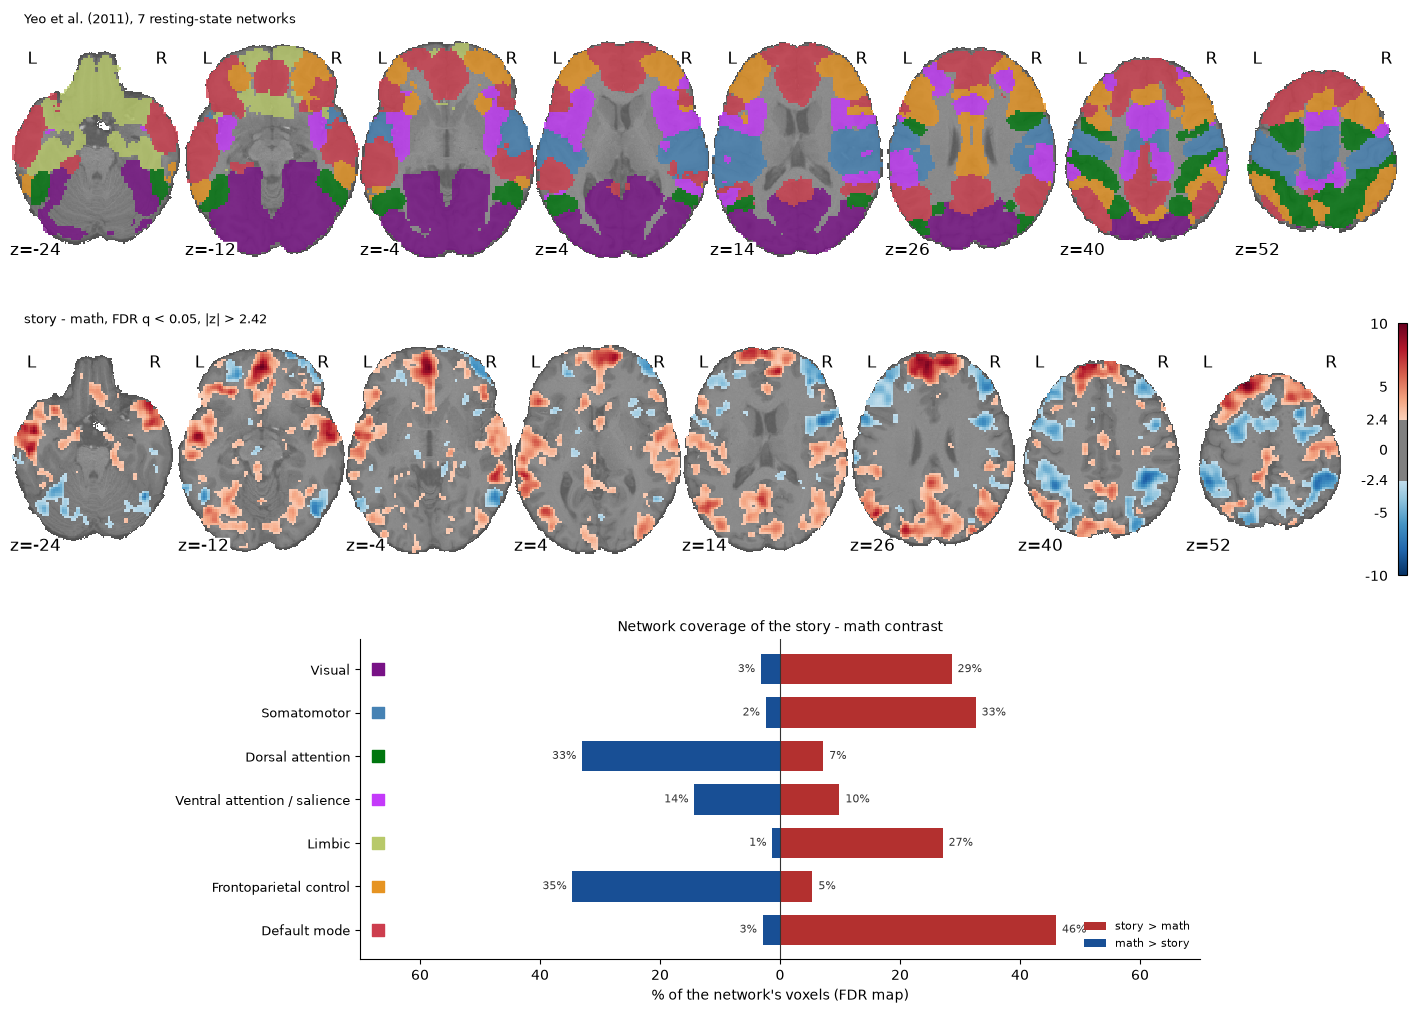

In [15]:
# Figure: Yeo networks on the same axial slices as the contrast, and the network coverage
from matplotlib.colors import ListedColormap as _ListedColormap

net_index = np.zeros(yeo_net.shape)
for k, net in enumerate(NETWORK_COLORS, start=1):
    net_index[yeo_net == net] = k
net_img = nib.Nifti1Image(net_index, z_img.affine)
yeo_cmap = _ListedColormap(list(NETWORK_COLORS.values()))

fig = plt.figure(figsize=(14, 10))
ax_net = fig.add_axes([0, 0.70, 1, 0.28])
ax_map = fig.add_axes([0, 0.40, 1, 0.28])
ax_bar = fig.add_axes([0.25, 0.03, 0.6, 0.32])
display = plotting.plot_roi(net_img, bg_img=anat_mni, display_mode="z", cut_coords=Z_CUTS, axes=ax_net,
                            cmap=yeo_cmap, vmin=0.5, vmax=7.5, alpha=0.8, black_bg=False, draw_cross=False,
                            colorbar=False)
display.title("Yeo et al. (2011), 7 resting-state networks", size=9, color="black", bgcolor="white")
display = plot_map(z_sm_thr, thr_sm, f"story - math, FDR q < {FDR_ALPHA}, |z| > {thr_sm:.2f}", ax_map)

nt = network_table.iloc[:-1][::-1]                                      # Yeo networks, first one on top
ypos = np.arange(len(nt))
ax_bar.barh(ypos, nt["coverage story>math (%)"], color="#b3302f", height=0.7, label="story > math")
ax_bar.barh(ypos, -nt["coverage math>story (%)"], color="#184f95", height=0.7, label="math > story")
for y, (s, m) in enumerate(zip(nt["coverage story>math (%)"], nt["coverage math>story (%)"])):
    ax_bar.text(s + 1, y, f"{s:.0f}%", va="center", fontsize=8, color="#333333")
    ax_bar.text(-m - 1, y, f"{m:.0f}%", va="center", ha="right", fontsize=8, color="#333333")
ax_bar.set_yticks(ypos, nt["network"], fontsize=9)
ax_bar.set_xlim(-70, 70)
ax_bar.scatter(np.full(len(nt), -67), ypos, marker="s", s=70,                     # network colour, as in the atlas
               c=[NETWORK_COLORS[n] for n in nt["network"]])
ax_bar.axvline(0, color="#333333", lw=0.8)
ax_bar.set_xticks(range(-60, 61, 20), [f"{abs(v)}" for v in range(-60, 61, 20)])
ax_bar.set_xlabel("% of the network's voxels (FDR map)")
ax_bar.set_title("Network coverage of the story - math contrast", fontsize=10)
ax_bar.legend(loc="lower right", frameon=False, fontsize=8)
ax_bar.spines[["top", "right"]].set_visible(False)
fig.savefig(op.join(fig_dir, "7e_networks.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 3f. Semantic language regions

Binder et al. (2011), the study this task comes from, designed the story vs math contrast to map the **anterior
temporal lobe (ATL)**, which most language localisers miss. Together with the semantic network of the
meta-analysis by Binder et al. (2009), the regions expected for story > math are, mostly left-lateralised:
- ATL: temporal pole, anterior superior / middle temporal gyrus (STS), and the **ventral ATL** (anterior
  inferior temporal and fusiform gyri, anterior parahippocampal gyrus);
- posterior middle temporal gyrus and angular gyrus;
- inferior frontal gyrus (pars triangularis / orbitalis), dorsomedial and ventromedial prefrontal cortex;
- posterior cingulate / precuneus.

For each region (Harvard-Oxford, split into left and right) we report the % of its voxels where story > math
(FDR map), the peak z, and two data-quality measures that tell whether the region could be detected at all:
the % of the region inside the functional brain mask, and the temporal SNR (mean / std over time) of the
motion-corrected, unsmoothed run.

In [16]:
BINDER_ROIS = {                                       # Harvard-Oxford cortical label -> short name
    "Temporal Pole": "temporal pole",
    "Superior Temporal Gyrus, anterior division": "ant. STG",
    "Middle Temporal Gyrus, anterior division": "ant. MTG",
    "Inferior Temporal Gyrus, anterior division": "ant. ITG (ventral ATL)",
    "Temporal Fusiform Cortex, anterior division": "ant. fusiform (ventral ATL)",
    "Parahippocampal Gyrus, anterior division": "ant. parahippocampal (ventral ATL)",
    "Middle Temporal Gyrus, posterior division": "post. MTG",
    "Angular Gyrus": "angular gyrus",
    "Inferior Frontal Gyrus, pars triangularis": "IFG triangularis",
    "Frontal Orbital Cortex": "orbitofrontal / IFG orbitalis",
    "Superior Frontal Gyrus": "dorsomedial PFC (SFG)",
    "Frontal Medial Cortex": "ventromedial PFC",
    "Cingulate Gyrus, posterior division": "posterior cingulate",
}

# Temporal SNR of the motion-corrected run before smoothing (part 1-2)
func_mc_brain = op.join(func_dir, "func_mc_brain.nii.gz")
mc_data = nib.load(func_mc_brain).get_fdata(dtype=np.float32)
mc_mean, mc_std = mc_data.mean(axis=3), mc_data.std(axis=3)
tsnr = np.divide(mc_mean, mc_std, out=np.zeros_like(mc_mean), where=mc_std > 0)
del mc_data
mni_brain_mask = datasets.load_mni152_brain_mask(resolution=2)            # whole-brain reference (MNI)
mni_brain = np.squeeze(image.resample_to_img(mni_brain_mask, z_img, interpolation="nearest").get_fdata()) > 0
tsnr_brain = np.median(tsnr[mask_data])

x_mm = z_img.affine[0, 0] * np.arange(z_img.shape[0]) + z_img.affine[0, 3]   # MNI x of each voxel column
left = np.broadcast_to(x_mm[:, None, None] < 0, z_img.shape[:3])

rows = []
for ho_label, short in BINDER_ROIS.items():
    roi_all = ho_cort_data == ho_cort.labels.index(ho_label)
    for side, hemi in (("L", left), ("R", ~left)):
        roi = roi_all & hemi & mni_brain
        roi_in = roi & mask_data
        rows.append({"region": short, "side": side,
                     "in func. mask (%)": 100 * roi_in.sum() / roi.sum(),
                     "median tSNR": np.median(tsnr[roi_in]) if roi_in.any() else 0,
                     "story>math (%)": 100 * (story_vox & roi).sum() / roi.sum(),
                     "math>story (%)": 100 * (math_vox & roi).sum() / roi.sum(),
                     "peak z": z_data[roi_in].max() if roi_in.any() else np.nan})
binder_table = pd.DataFrame(rows).round(1)
binder_table.to_csv(op.join(glm_dir, "binder_regions_story_minus_math.csv"), index=False)
print(f"Median tSNR of the brain: {tsnr_brain:.1f}")
print(binder_table.to_string(index=False))

Median tSNR of the brain: 32.6
                            region side  in func. mask (%)  median tSNR  story>math (%)  math>story (%)  peak z
                     temporal pole    L               91.9    24.900000            63.6             0.0     7.9
                     temporal pole    R               95.3    25.700001            56.3             0.0     8.3
                          ant. STG    L              100.0    36.599998            99.6             0.0    10.2
                          ant. STG    R              100.0    35.299999            92.2             0.0     8.8
                          ant. MTG    L              100.0    34.200001            93.0             0.0     9.2
                          ant. MTG    R              100.0    32.400002            71.8             0.0     8.8
            ant. ITG (ventral ATL)    L               98.5    24.900000            27.6             0.0     6.4
            ant. ITG (ventral ATL)    R               91.2    26.200001  

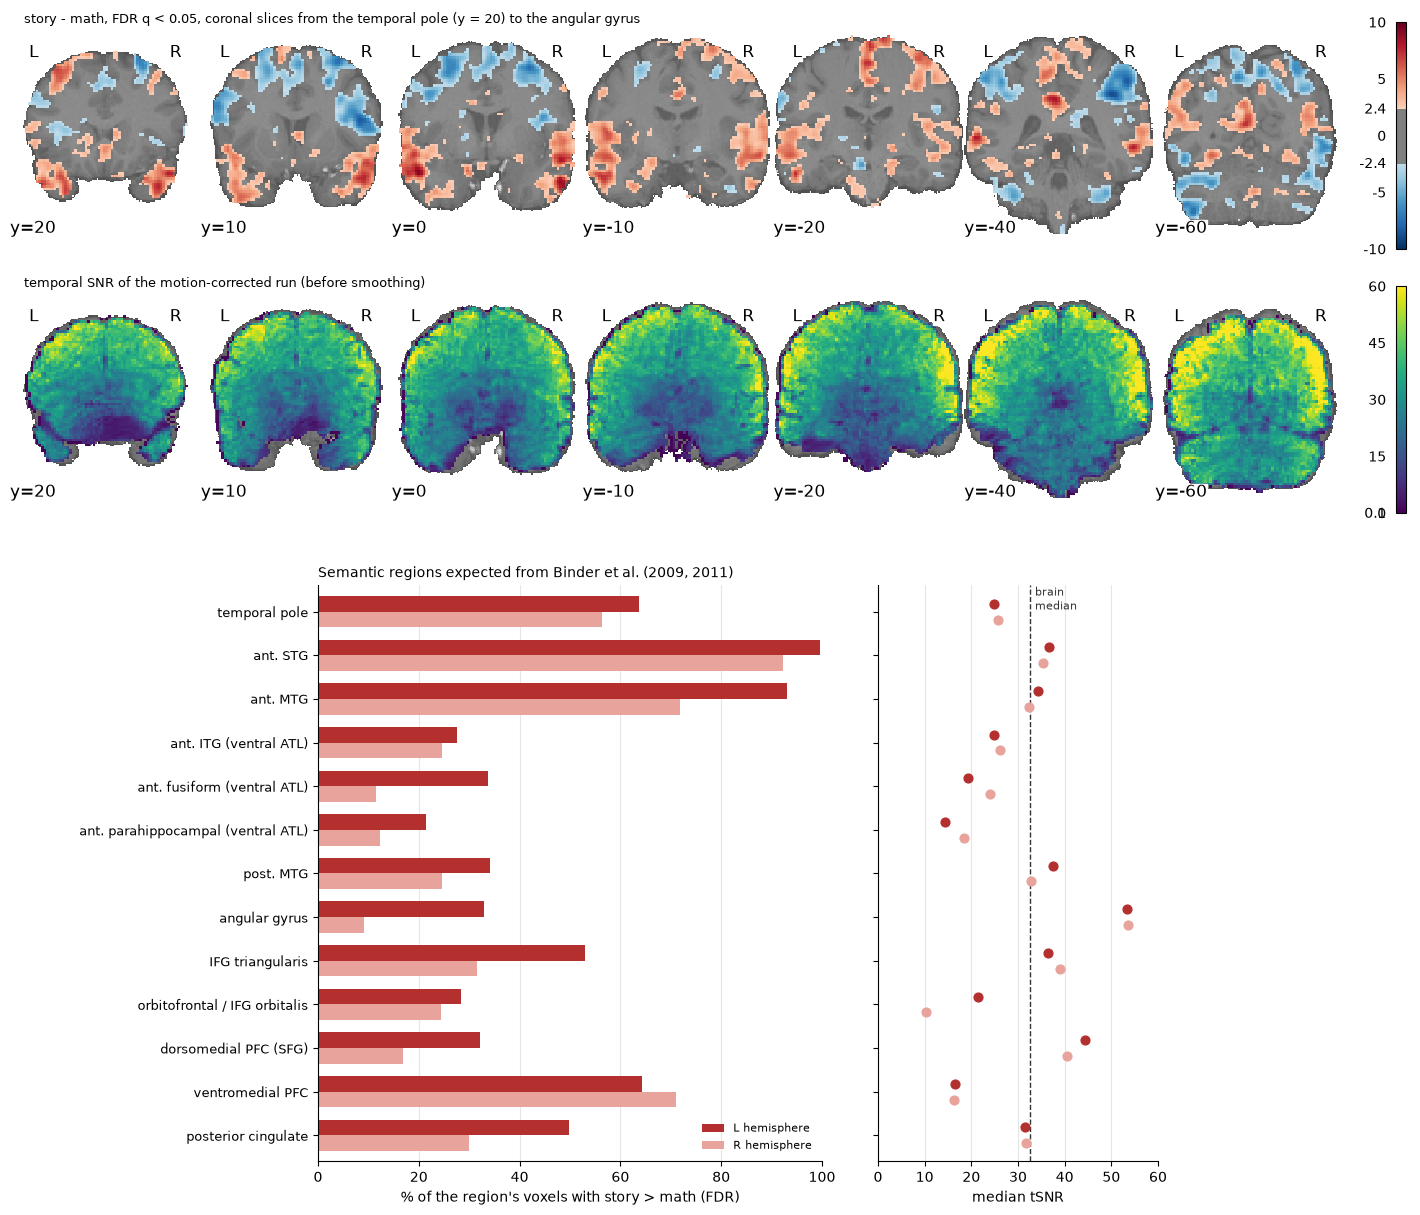

In [17]:
# Figure: coronal slices through the ATL (contrast and tSNR), and the expected regions
Y_CUTS = [20, 10, 0, -10, -20, -40, -60]                                 # temporal pole -> angular gyrus
tsnr_img = nib.Nifti1Image(np.where(mask_data, tsnr, 0), z_img.affine)

fig = plt.figure(figsize=(14, 12))
ax_c = fig.add_axes([0, 0.78, 1, 0.21])
ax_t = fig.add_axes([0, 0.56, 1, 0.21])
ax_r = fig.add_axes([0.22, 0.03, 0.36, 0.48])
ax_s = fig.add_axes([0.62, 0.03, 0.2, 0.48])
display = plotting.plot_stat_map(z_sm_thr, bg_img=anat_mni, display_mode="y", cut_coords=Y_CUTS, axes=ax_c,
                                 threshold=thr_sm, vmax=Z_VMAX, cmap="RdBu_r", black_bg=False, draw_cross=False)
display.title(f"story - math, FDR q < {FDR_ALPHA}, coronal slices from the temporal pole (y = 20) to the angular gyrus",
              size=9, color="black", bgcolor="white")
display = plotting.plot_stat_map(tsnr_img, bg_img=anat_mni, display_mode="y", cut_coords=Y_CUTS, axes=ax_t,
                                 cmap="viridis", vmin=0, vmax=60, threshold=0.1, symmetric_cbar=False,
                                 black_bg=False, draw_cross=False)
display.title("temporal SNR of the motion-corrected run (before smoothing)", size=9, color="black", bgcolor="white")

regions = list(BINDER_ROIS.values())[::-1]
ypos = np.arange(len(regions))
bt = binder_table.set_index(["region", "side"])
L_COLOR, R_COLOR = "#b3302f", "#e8a39c"                                  # left darker: the expected dominant side
for side, color, dy in (("L", L_COLOR, 0.18), ("R", R_COLOR, -0.18)):
    ax_r.barh(ypos + dy, [bt.loc[(r, side), "story>math (%)"] for r in regions], height=0.36, color=color,
              label=f"{side} hemisphere")
    ax_s.scatter([bt.loc[(r, side), "median tSNR"] for r in regions], ypos + dy, color=color, s=40, zorder=3)
ax_r.set_yticks(ypos, regions, fontsize=9)
ax_r.set_xlim(0, 100)
ax_r.set_xlabel("% of the region's voxels with story > math (FDR)")
ax_r.legend(loc="lower right", frameon=False, fontsize=8)
ax_s.axvline(tsnr_brain, color="#333333", ls="--", lw=1)
ax_s.text(tsnr_brain + 1, len(regions) - 0.4, "brain\nmedian", fontsize=8, color="#333333", va="top")
ax_s.set_yticks(ypos, [])
ax_s.set_xlim(0, 60)
ax_s.set_xlabel("median tSNR")
for ax in (ax_r, ax_s):
    ax.set_ylim(-0.6, len(regions) - 0.4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="0.9")
    ax.set_axisbelow(True)
ax_r.set_title("Semantic regions expected from Binder et al. (2009, 2011)", fontsize=10, loc="left")
fig.savefig(op.join(fig_dir, "7f_semantic_regions.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on 3e

(`7e_networks.png`, `networks_story_minus_math.csv`, `peaks_story_minus_math_labelled.csv`)

**Math > story (numerical processing): dorsal attention and frontoparietal control networks.** These two
networks hold 57% of the math > story voxels, and a third of each network is more active during math (33% and
35% coverage, mean z -1.3 and -1.4). The peaks are in the bilateral intraparietal sulcus / posterior
supramarginal gyrus ((40, -40, 38), (-52, -46, 56)), the superior parietal lobule, the right middle frontal
gyrus and frontal eye field region ((36, 6, 64)) and the dorsolateral prefrontal cortex ((42, 42, 22),
(-48, 30, 36)). The intraparietal sulcus holds the representation of numerical quantity, and the frontoparietal
network supports the working memory and the step-by-step control of mental arithmetic. The posterior
cerebellum and the inferior occipito-temporal cortex are also more active during math.

**Story > math (semantic processing): default mode network first.** It holds 38% of the story > math voxels,
and 46% of the network is more active during the stories (mean z 2.3). Peaks: medial prefrontal cortex /
frontal pole ((-4, 60, 28), (0, 56, -8)), posterior cingulate / precuneus ((-2, -42, 34)), angular gyrus /
lateral parietal, and the lateral temporal cortex from the temporal pole to the posterior STS
((-54, -4, -10), (60, -4, -14), (-64, -40, 4)). This is the overlap between the default mode network and the
semantic network (Binder et al., 2009): comprehension of a narrative uses the same regions as internally
directed, memory-based thinking, whereas the effortful math task deactivates them.
Three other networks are more active during the stories:
- **limbic** (27% coverage): temporal poles and orbitofrontal cortex, i.e. the ATL (see 3f);
- **somatomotor** (33%): in Yeo's 7-network atlas this network includes the auditory cortex and the
  superior temporal plane. Listening to a continuous story is a richer auditory and speech input than the
  short math problems; the medial premotor peaks may also reflect speech-related motor activity;
- **visual** (29%), on the lateral and dorsal occipital cortex and the cuneus: there is no visual stimulus in
  either task, so this is either visual imagery during the narrative, or a stronger deactivation of the
  visual cortex during math (the single-condition maps cannot tell, 3c).

The ventral attention / salience network is split (10% story > math, 14% math > story).
Caveat: the atlas is defined at the group level and our data are a single subject, so the overlap is
approximate; the networks are counted after a 4 mm dilation of the atlas (see above).

### Comments on 3f

(`7f_semantic_regions.png`, `binder_regions_story_minus_math.csv`)

**The expected semantic regions are present in the story > math map**, in both hemispheres:
- lateral ATL: anterior STG (L 99.6% of voxels, peak z 10.2), anterior MTG (L 93%), temporal pole (L 64%,
  R 56%). This is the main finding of Binder et al. (2011);
- posterior MTG, left angular gyrus, left IFG pars triangularis (53%), ventromedial PFC (64-71%),
  dorsomedial PFC and posterior cingulate.
The left side dominates in most regions (angular gyrus, IFG, posterior cingulate, fusiform), as expected for
language, but the ATL activation is strongly bilateral, also in agreement with Binder et al. (2011). The right
angular gyrus is more active during math (39% math > story): the Harvard-Oxford angular gyrus extends into the
intraparietal sulcus.

**The ventral ATL is the weak spot**: only 12-34% of the anterior inferior temporal, fusiform and
parahippocampal gyri pass the threshold, against > 70% for the lateral ATL, with lower peak z (4.1-6.6).
Two reasons can explain it:
1. **Susceptibility artefacts.** The ventral ATL lies just above the air-filled sinuses and ear canals. The
   magnetic field inhomogeneity there causes signal dropout and distortion in gradient-echo EPI. The data show
   it: the median tSNR is 14-26 in the ventral ATL and 10-21 in the orbitofrontal cortex, against 33 for the brain
   and 53 in the angular gyrus, and part of these regions is outside the functional mask (82% of the left
   anterior fusiform is inside). Lower tSNR means lower z for the same effect. This is precisely why Binder et
   al. (2011) needed an optimised acquisition to map the ventral ATL. (HCP corrects the distortion with field
   maps, but cannot recover the lost signal.)
2. **The contrast removes what is shared.** Math problems are also spoken sentences that must be understood
   and answered, so the story - math subtraction cancels the shared auditory, phonological and syntactic
   processing, and part of the semantic processing (number words have meaning). Regions that are engaged by
   both tasks, even if they are semantic, are reduced in the contrast.

Other factors: a single subject and a single 3.75-min run (low power; the second run of HCP would help); the
6 mm smoothing, which mixes the thin ventral ATL cortex with the low-signal voxels next to it; and the
group-level atlas boundaries, which do not match this subject's anatomy exactly.